# Лабораторная работа №2

Тема: морфологический анализ, частеречная разметка (POS-tagging) и извлечение синтаксических структур.

Датасет: AG News, тот же, что и в первой работе.

## 1. Частеречная разметка (POS-tagging)

### 1.1 Загрузка данных и очистка

In [1]:
import re
import html
import unicodedata
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

In [ ]:
# если библиотеки нет: !pip install datasets
from datasets import load_dataset

raw = load_dataset('fancyzhx/ag_news')

df = pd.DataFrame(raw['train'])
df['label'] = df['label'] + 1  # в HuggingFace метки 0-3, сдвигаю на 1-4

print(f'Размер датасета: {df.shape}')
df.head(3)

In [3]:
LABEL_MAP = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}
df['category'] = df['label'].map(LABEL_MAP)

train_df, test_df = train_test_split(
    df[['text', 'label', 'category']],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df['label'],
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'Train: {len(train_df)}, Test: {len(test_df)}')

Train: 96000, Test: 24000


Разбиение и очистка те же, что в первой работе. Из конвейера очистки беру только токенизацию и замену шума, регистр букв сохраняю: тэггер использует заглавные буквы как признак (имена, начало предложения), поэтому приводить текст к нижнему регистру перед разметкой нельзя.

In [4]:
RE_HTML_TAG = re.compile(r'<[^>]+>')
RE_ENTITY_NO_AMP = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')
RE_URL = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
RE_EMAIL = re.compile(r'\b[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}\b')
RE_TRAIL_SEMI = re.compile(r'\s*;\s*$')
RE_ELLIPSIS = re.compile(r'\.{2,}')
RE_LQUOTE = re.compile(r'[\u2018\u201c\u00ab]')
RE_RQUOTE = re.compile(r'[\u201d\u00bb]')
RE_APOSTROPHE = re.compile(r'\u2019')
RE_DASH = re.compile(r'[\u2013\u2014\u2015]')
RE_NUMBER = re.compile(r'(?<![A-Za-z\-.,])\b\d+([.,]\d+)*\b(?![A-Za-z\-])')
RE_BACKSLASH = re.compile(r'\\+')
RE_LONE_HASH = re.compile(r'#(?=[^a-zA-Z]|$)')
RE_TOKEN = re.compile(r'\[(?:NUM|URL|EMAIL)\]|\w+(?:[-.]\w+)*|[^\w\s]')


def clean_tokens(text):
    text = RE_ENTITY_NO_AMP.sub(r'&\1;', text)
    text = html.unescape(text)
    text = RE_HTML_TAG.sub(' ', text)
    text = RE_URL.sub('[URL]', text)
    text = RE_EMAIL.sub('[EMAIL]', text)
    text = RE_TRAIL_SEMI.sub('', text)
    text = RE_ELLIPSIS.sub('.', text)
    text = RE_LQUOTE.sub('"', text)
    text = RE_RQUOTE.sub('"', text)
    text = RE_APOSTROPHE.sub("'", text)
    text = RE_DASH.sub('-', text)
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', errors='ignore').decode('ascii')
    text = RE_NUMBER.sub('[NUM]', text)
    text = RE_BACKSLASH.sub(' ', text)
    text = RE_LONE_HASH.sub(' ', text)
    return RE_TOKEN.findall(text)


train_df['tokens'] = train_df['text'].apply(clean_tokens)
test_df['tokens'] = test_df['text'].apply(clean_tokens)

print(train_df['tokens'].iloc[0])

['Clijsters', 'Unsure', 'About', 'Latest', 'Injury', ',', 'Says', 'Hewitt', 'TOKYO', '(', 'Reuters', ')', '-', 'Belgian', 'Kim', 'Clijsters', 'is', 'unsure', 'about', 'the', 'exact', 'nature', 'of', 'the', 'injury', 'that', 'has', 'prematurely', 'ended', 'her', 'season', ',', 'her', 'fiance', 'Lleyton', 'Hewitt', 'said', 'on', 'Wednesday', '.']


### 1.2 Загрузка тэггера

Для разметки использую spaCy с моделью `en_core_web_sm`. Она даёт для каждого токена два тега: `pos_` (универсальные части речи Universal Dependencies, 17 классов) и `tag_` (детальные теги Penn Treebank, например `NN`, `NNS`, `VBD`). Из конвейера оставляю только компоненты, нужные для разметки: `tok2vec`, `tagger` и `attribute_ruler`, который по `tag_` выставляет `pos_`. Остальные компоненты отключены, чтобы разметка шла быстрее.

In [5]:
# если модели нет: !python -m spacy download en_core_web_sm
import spacy
from spacy.tokens import Doc

nlp = spacy.load('en_core_web_sm', exclude=['parser', 'ner', 'lemmatizer'])
print(nlp.pipe_names)

['tok2vec', 'tagger', 'attribute_ruler']


### 1.3 Разметка корпуса

Тексты уже разбиты на токены, поэтому передаю в spaCy готовые списки слов через `Doc(words=...)`. Так токенизатор spaCy не пересекается с нашей токенизацией, и число тегов в точности равно числу токенов.

In [6]:
def pos_tag_corpus(token_lists, batch_size=512):
    docs = (Doc(nlp.vocab, words=toks) for toks in token_lists)
    pos_all, tag_all = [], []
    for doc in nlp.pipe(docs, batch_size=batch_size):
        pos_all.append([t.pos_ for t in doc])
        tag_all.append([t.tag_ for t in doc])
    return pos_all, tag_all


train_df['pos'], train_df['tag'] = pos_tag_corpus(train_df['tokens'])
test_df['pos'], test_df['tag'] = pos_tag_corpus(test_df['tokens'])

print(f'Размечено документов: Train {len(train_df):,}, Test {len(test_df):,}')
print(f'Размечено токенов в Train: {train_df["pos"].str.len().sum():,}')

Размечено документов: Train 96,000, Test 24,000
Размечено токенов в Train: 4,102,755


### 1.4 Результат разметки

In [7]:
def show_tagged(row, n=15):
    return pd.DataFrame({
        'token': row['tokens'][:n],
        'pos': row['pos'][:n],
        'tag': row['tag'][:n],
    }).T

print(train_df['category'].iloc[0])
show_tagged(train_df.iloc[0])

Sports


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,Clijsters,Unsure,About,Latest,Injury,",",Says,Hewitt,TOKYO,(,Reuters,),-,Belgian,Kim
pos,PROPN,PROPN,ADP,PROPN,PROPN,PUNCT,VERB,PROPN,PROPN,PUNCT,PROPN,PUNCT,PUNCT,PROPN,PROPN
tag,NNP,NNP,IN,NNP,NNP,",",VBZ,NNP,NNP,-LRB-,NNP,-RRB-,:,NNP,NNP


In [8]:
for i in range(1, 4):
    row = train_df.iloc[i]
    print(row['category'])
    print(' '.join(f'{w}/{p}' for w, p in zip(row['tokens'], row['pos'])))
    print()

Sci/Tech
Earthquake/PROPN Swarm/PROPN Shakes/PROPN Eastern/PROPN Sierra/PROPN (/PUNCT AP/PROPN )/PUNCT AP/PROPN -/PUNCT A/DET swarm/NOUN of/ADP earthquakes/NOUN -/PUNCT one/NUM a/DET magnitude-5.5/NUM -/PUNCT jolted/VERB a/DET remote/ADJ ,/PUNCT sparsely/ADV populated/ADJ area/NOUN along/ADP the/DET eastern/ADJ Sierra/PROPN Nevada/PROPN on/ADP Saturday/PROPN ,/PUNCT authorities/NOUN said/VERB ./PUNCT

World
Issues/NOUN related/VERB to/ADP war/NOUN in/ADP Iraq/PROPN help/AUX define/VERB election/NOUN in/ADP Australia/PROPN SYDNEY/PROPN -/PUNCT -/PUNCT On/ADP one/NUM side/NOUN is/AUX the/DET incumbent/NOUN ,/PUNCT a/DET conservative/ADJ career/NOUN politician/NOUN who/PRON steadfastly/ADV defends/VERB his/PRON decision/NOUN to/PART send/VERB troops/NOUN to/ADP Iraq/PROPN ./PUNCT

Sports
NCAA/PROPN probation/NOUN for/ADP little/ADJ engine/NOUN that/PRON could/AUX ROMEOVILLE/NOUN ,/PUNCT Ill/PROPN ./PUNCT The/DET Division/PROPN Two/NUM school/NOUN that/PRON won/VERB an/DET NCAA/PROPN Divis

#### Частоты тегов

In [9]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

pos_counts = Counter(p for seq in train_df['pos'] for p in seq)
tag_counts = Counter(t for seq in train_df['tag'] for t in seq)
total = pos_counts.total()

pos_table = pd.DataFrame(pos_counts.most_common(), columns=['pos', 'tokens'])
pos_table['share, %'] = (pos_table['tokens'] / total * 100).round(2)
pos_table

,pos,tokens,"share, %"
0,PROPN,815238,19.87
1,NOUN,808981,19.72
2,ADP,450738,10.99
3,PUNCT,440994,10.75
4,VERB,413459,10.08
5,DET,291038,7.09
6,ADJ,269386,6.57
7,PART,120762,2.94
8,AUX,116072,2.83
9,PRON,101522,2.47


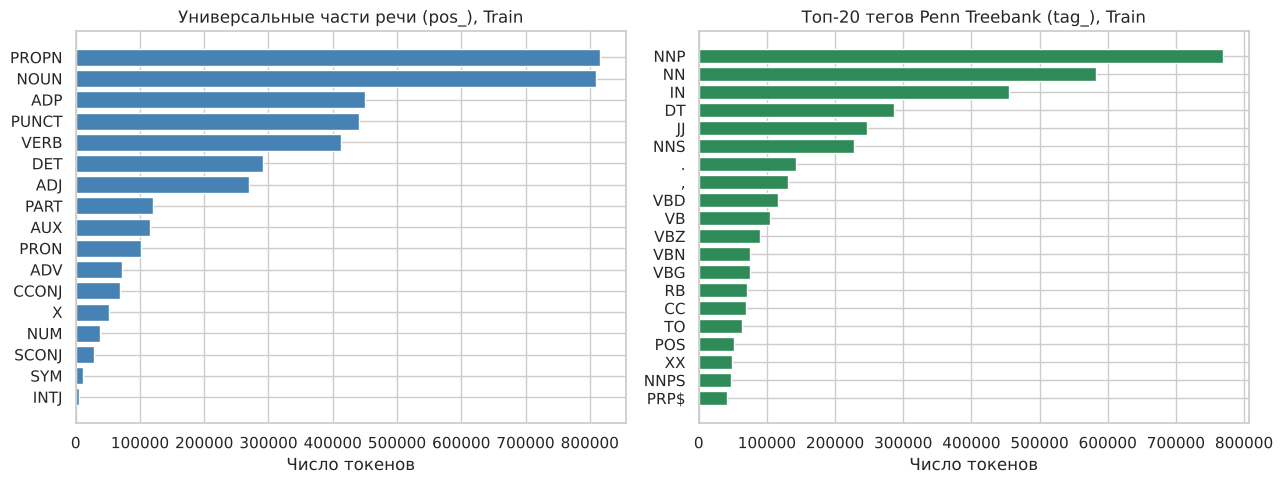

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

labels, freqs = zip(*pos_counts.most_common())
axes[0].barh(labels, freqs, color='steelblue')
axes[0].invert_yaxis()
axes[0].set_title('Универсальные части речи (pos_), Train')
axes[0].set_xlabel('Число токенов')

labels, freqs = zip(*tag_counts.most_common(20))
axes[1].barh(labels, freqs, color='seagreen')
axes[1].invert_yaxis()
axes[1].set_title('Топ-20 тегов Penn Treebank (tag_), Train')
axes[1].set_xlabel('Число токенов')

plt.tight_layout()
plt.show()

Тэггер разметил все токены: число тегов в каждом документе совпадает с числом токенов. Распределение частей речи типично для новостного текста. Существительные (`NOUN`, 19.7%) и имена собственные (`PROPN`, 19.9%) вместе дают около 40% токенов, что объясняется обилием названий организаций, людей, стран и городов в заголовках и первых предложениях. Дальше идут предлоги (`ADP`, 11.0%), знаки препинания (`PUNCT`, 10.8%), глаголы (`VERB`, 10.1%), артикли и указатели (`DET`, 7.1%) и прилагательные (`ADJ`, 6.6%). Наречий (1.7%) и междометий (0.1%) мало, что тоже ожидаемо для делового и новостного стиля.

Среди детальных тегов Penn Treebank лидируют `NNP`, `NN`, `IN`, `DT`, `JJ` и `NNS`, затем идут знаки препинания и глагольные формы `VBD`, `VB`, `VBZ`, `VBN`, `VBG`.

Заметные ошибки есть в заголовках, записанных заглавными буквами или с заглавной буквы у каждого слова: например, `Latest` и `Injury` в первом примере помечены как `PROPN`, а `ROMEOVILLE` в третьем как `NOUN`. Служебные токены `[NUM]` и `[URL]` модель не знает, поэтому чаще всего помечает их как `X` (1.25% токенов), иногда ошибочно как другую часть речи.

## 2. Анализ распределения частей речи

### 2.1 Распределение по всему корпусу

Корпусом считаю обе части датасета, Train и Test вместе: тэггер не обучается на этих данных, поэтому утечки нет.

In [11]:
corpus_df = pd.concat([train_df, test_df], ignore_index=True)

pos_counts = Counter(p for seq in corpus_df['pos'] for p in seq)
total = pos_counts.total()

pos_table = pd.DataFrame(pos_counts.most_common(), columns=['pos', 'tokens'])
pos_table['share, %'] = (pos_table['tokens'] / total * 100).round(2)

print(f'Документов: {len(corpus_df):,}, токенов: {total:,}')
pos_table

Документов: 120,000, токенов: 5,125,446


,pos,tokens,"share, %"
0,PROPN,1019228,19.89
1,NOUN,1010046,19.71
2,ADP,563056,10.99
3,PUNCT,550875,10.75
4,VERB,516538,10.08
5,DET,363711,7.10
6,ADJ,336695,6.57
7,PART,151104,2.95
8,AUX,145015,2.83
9,PRON,126973,2.48


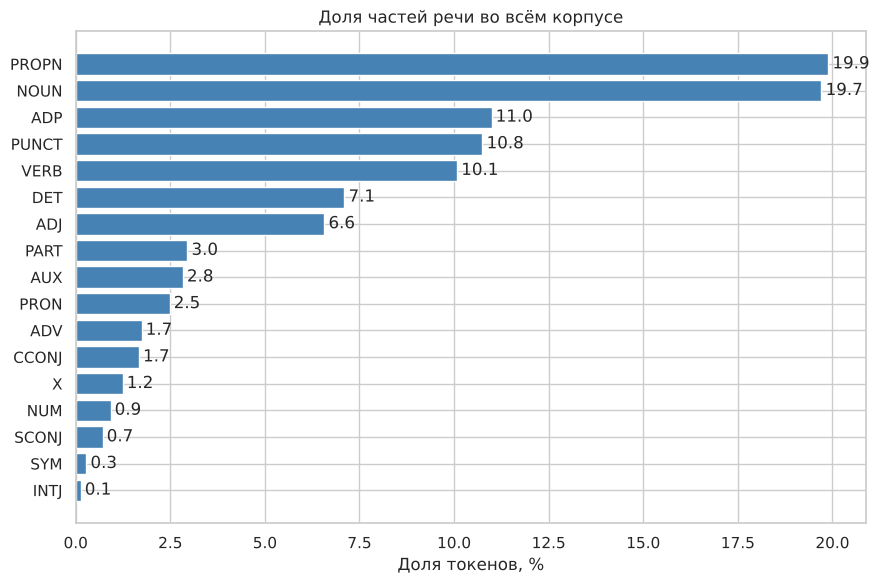

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(pos_table['pos'], pos_table['share, %'], color='steelblue')
ax.invert_yaxis()
ax.bar_label(bars, fmt='%.1f', padding=3)
ax.set_title('Доля частей речи во всём корпусе')
ax.set_xlabel('Доля токенов, %')
plt.tight_layout()
plt.show()

Во всём корпусе (120 000 документов, около 5.1 млн токенов) первые два места занимают имена собственные (`PROPN`, 19.9%) и существительные (`NOUN`, 19.7%), вместе почти 40% токенов. Следом идут предлоги (`ADP`, 11.0%), знаки препинания (`PUNCT`, 10.8%) и глаголы (`VERB`, 10.1%). Артикли и указатели (`DET`) дают 7.1%, прилагательные (`ADJ`) 6.6%, а остальные классы (частицы, вспомогательные глаголы, местоимения, наречия, союзы, числительные) занимают меньше 3% каждый. Междометий (`INTJ`) всего 0.13%.

Такая структура типична для новостей: в заголовках и первых предложениях много названий людей, организаций и мест, а глаголы стоят в основном в форме прошедшего или настоящего времени.

### 2.2 Части речи по классам документов

Для каждого класса считаю долю каждой части речи среди всех токенов этого класса. Доли, а не абсолютные числа, потому что тексты разной длины и классы по объёму токенов не совпадают.

In [13]:
class_pos = {}
for cat, group in corpus_df.groupby('category'):
    cnt = Counter(p for seq in group['pos'] for p in seq)
    class_pos[cat] = pd.Series(cnt) / cnt.total() * 100

class_table = pd.DataFrame(class_pos).fillna(0)
class_table = class_table.loc[pos_table['pos']]
class_table.round(2)

,Business,Sci/Tech,Sports,World
PROPN,19.01,17.40,23.47,19.67
NOUN,21.43,21.45,16.56,19.39
ADP,10.89,10.17,11.08,11.78
PUNCT,11.14,11.09,10.45,10.32
VERB,10.05,10.37,9.23,10.64
DET,6.30,7.04,8.03,7.04
ADJ,6.53,6.66,5.60,7.47
PART,2.92,2.88,2.82,3.17
AUX,2.40,3.36,2.85,2.72
PRON,2.20,2.78,2.83,2.10


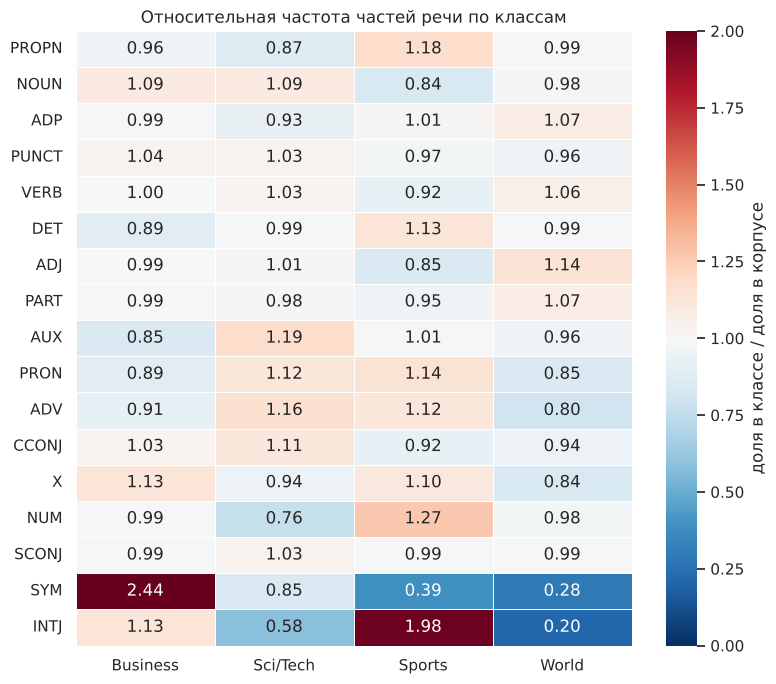

In [14]:
corpus_share = pos_table.set_index('pos')['share, %']
relative = class_table.div(corpus_share, axis=0)

plt.figure(figsize=(8, 7))
sns.heatmap(relative, annot=True, fmt='.2f', cmap='RdBu_r', center=1.0, vmin=0, vmax=2,
            linewidths=0.5, cbar_kws={'label': 'доля в классе / доля в корпусе'})
plt.title('Относительная частота частей речи по классам')
plt.ylabel('')
plt.xlabel('')
plt.tight_layout()
plt.show()

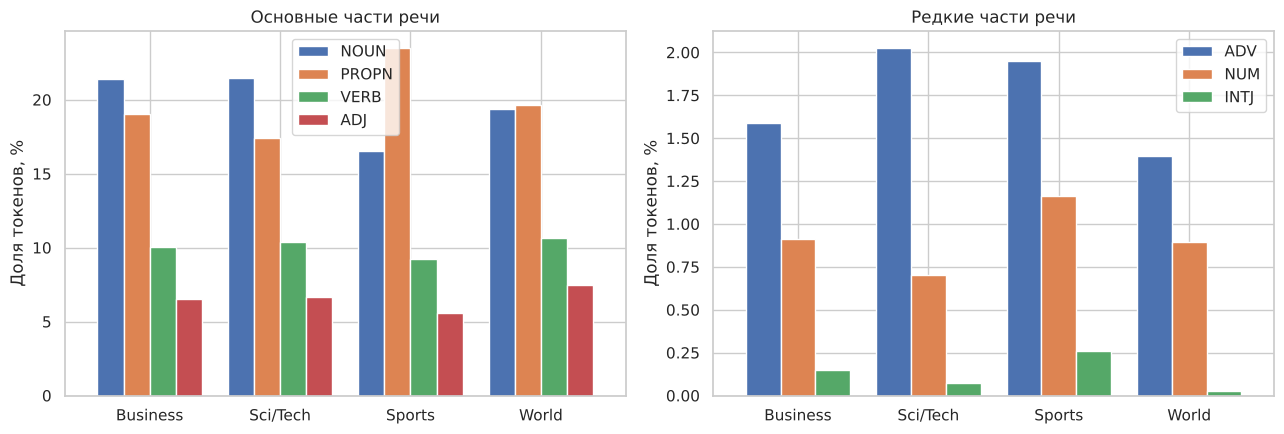

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

class_table.loc[['NOUN', 'PROPN', 'VERB', 'ADJ']].T.plot(kind='bar', ax=axes[0], width=0.8, rot=0)
axes[0].set_title('Основные части речи')
axes[0].set_ylabel('Доля токенов, %')

class_table.loc[['ADV', 'NUM', 'INTJ']].T.plot(kind='bar', ax=axes[1], width=0.8, rot=0)
axes[1].set_title('Редкие части речи')
axes[1].set_ylabel('Доля токенов, %')

plt.tight_layout()
plt.show()

Междометий мало, но их доля по классам отличается заметнее всего, поэтому смотрю, какие слова получили тег `INTJ` в каждом классе.

In [16]:
for cat, group in corpus_df.groupby('category'):
    words = Counter(w for toks, tags in zip(group['tokens'], group['pos'])
                    for w, p in zip(toks, tags) if p == 'INTJ')
    print(f'{cat}: {words.most_common(6)}')

Business: [('Quote', 1007), ('No', 361), ('O', 71), ('OK', 62), ('ll', 37), ('Oracle', 27)]
Sci/Tech: [('Quote', 190), ('No', 103), ('ll', 89), ('Well', 62), ('O', 43), ('Oracle', 26)]
Sports: [('No', 1847), ('O', 328), ('p.m', 241), ('vs', 112), ('ll', 99), ('right', 39)]


World: [('No', 80), ('ll', 29), ('OK', 24), ('O', 19), ('yes', 12), ('right', 12)]


Различия между классами заметны для нескольких частей речи.

- Sports: имён собственных больше всего (23.5% при среднем 19.9%), а нарицательных существительных меньше всего (16.6% при 19.7%). В спортивных новостях в основном называются игроки, тренеры и команды. Прилагательных тоже меньше всего (5.6%), артиклей и указателей больше всех (8.0%).
- World: больше всего прилагательных (7.5%) и глаголов (10.6%), меньше всего наречий (1.4%). Самые частые прилагательные в этом классе это `Iraqi`, `Palestinian`, `Israeli`, `nuclear`: международные новости описывают страны и конфликты относительными прилагательными.
- Business и Sci/Tech по структуре близки: существительных по 21.4%, имён собственных меньше, чем в Sports и World. Business выделяется долей `SYM` (0.68%, в 2.4 раза выше среднего): почти все такие токены это знак доллара. В Sci/Tech больше всего вспомогательных глаголов (3.4%) и наречий (2.0%).
- Междометия: доля в Sports 0.26%, в Business 0.15%, в Sci/Tech 0.08%, в World 0.03%. Но по списку слов видно, что это почти не междометия: в Sports и World тег `INTJ` получили в основном `No` из выражений вида `No. 1`, в Business слово `Quote` из шаблона Reuters со ссылками на котировки. Реальные междометия (`Well`, `OK`, `Yes`, `Boy`) встречаются редко. Поэтому различие по междометиям отражает шаблоны и ошибки тэггера, а не стиль класса.

В целом части речи различаются по классам умеренно: самые сильные отклонения от среднего у `PROPN` (+18%) и `NOUN` (-16%) в Sports и у `SYM` в Business, остальные частые классы отклоняются от среднего меньше, чем на 20%.

### 2.3 Ошибки тэггера

Ошибки ищу прямым просмотром корпуса: беру слова и шаблоны, где разметка явно неверна, и показываю первое вхождение в корпусе вместе с окружением (`токен/pos`). Во всех примерах разметка получена на очищенном тексте, как в разделе 1.

In [17]:
def find_context(word, pos, prev=None, left=6, right=6):
    for toks, tags, cat in zip(corpus_df['tokens'], corpus_df['pos'], corpus_df['category']):
        for i, (w, p) in enumerate(zip(toks, tags)):
            if w == word and p == pos and (prev is None or (i > 0 and toks[i - 1] == prev)):
                lo, hi = max(0, i - left), i + right + 1
                return cat, ' '.join(f'{a}/{b}' for a, b in zip(toks[lo:hi], tags[lo:hi]))
    return None, None


cases = [
    ('ADVERTISEMENT', 'VERB', None),
    ('nbsp', 'NOUN', None),
    ('RWANDAN', 'NOUN', None),
    ('[NUM]', 'ADP', '$'),
    ('blog', 'VERB', 'makes'),
    ('wi-fi', 'ADP', None),
    ('Quote', 'INTJ', None),
    ('s', 'X', "'"),
    ('8bn', 'ADJ', '.'),
]

rows = []
for word, pos, prev in cases:
    cat, context = find_context(word, pos, prev)
    rows.append({'токен': word, 'pos': pos, 'класс': cat, 'контекст': context})

pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows)

,токен,pos,класс,контекст
0,ADVERTISEMENT,VERB,Sci/Tech,service/NOUN providers/NOUN (/PUNCT ISPs/NOUN )/PUNCT ./PUNCT ADVERTISEMENT/VERB Solaris/PROPN [NUM]/X (/PUNCT TM/PROPN )/PUNCT OS/NOUN
1,nbsp,NOUN,Sci/Tech,NASA/PROPN is/AUX reviewing/VERB a/DET list/NOUN of/ADP nbsp/NOUN ;/PUNCT fission-powered/VERB missions/NOUN that/PRON could/AUX pre-empt/VERB
2,RWANDAN,NOUN,World,RWANDAN/NOUN TROOPS/NOUN CROSS/VERB INTO/ADP DR/PROPN CONGO/PROPN The/DET
3,[NUM],ADP,Business,it/PRON extract/VERB new/ADJ concessions/NOUN worth/ADJ $/SYM [NUM]/ADP million/NUM a/DET year/NOUN from/ADP employees/NOUN as/ADP
4,blog,VERB,Sci/Tech,US/PROPN :/PUNCT US/PROPN election/NOUN makes/VERB blog/VERB the/DET word/NOUN of/ADP the/DET year/NOUN A/DET
5,wi-fi,ADP,Sci/Tech,been/AUX made/VERB to/PART re-assure/VERB businesses/NOUN that/PRON wi-fi/ADP networks/NOUN can/AUX be/AUX made/VERB safe/ADJ enough/ADV
6,Quote,INTJ,Sci/Tech,"Networks/PROPN Corp/PROPN ./PUNCT (/PUNCT NT.TO/PROPN :/PUNCT Quote/INTJ ,/PUNCT Profile/PROPN ,/PUNCT Research/PROPN )/PUNCT said/VERB"
7,s,X,Business,shoppers/NOUN get/VERB their/PRON holiday/NOUN money/NOUN '/PUNCT s/X worth/NOUN on/ADP the/DET biggest/ADJ shopping/NOUN day/NOUN
8,8bn,ADJ,Business,[NUM]/X ./PUNCT 2bn/NOUN (/PUNCT [NUM]/X ./PUNCT 8bn/ADJ )/PUNCT takeover/NOUN bid/NOUN for/ADP its/PRON rival/NOUN


Разобранные примеры (в таблице выше показано первое вхождение в корпусе):

1. `ADVERTISEMENT` помечено как `VERB`. Это остаток рекламного блока из веб-страницы: слово написано заглавными, стоит после точки и перед названием продукта, и тэггер выбирает для него глагол.
2. `nbsp` помечено как `NOUN`. В исходных текстах есть дважды закодированная сущность `&amp;nbsp;`. После декодирования остаётся `nbsp ;`, и тэггер принимает остаток за существительное.
3. `RWANDAN` помечено как `NOUN`. В заголовке, набранном заглавными буквами, прилагательное принято за существительное. Когда все слова написаны заглавными, у модели нет опоры на регистр, и она ошибается в частях речи. Дальше в том же заголовке имена `DR CONGO` размечены верно.
4. `[NUM]` после знака доллара помечено как `ADP` (в других местах как `X` или `NOUN`). Служебный токен не встречался тэггеру при обучении, поэтому его тег определяется только по соседним словам и в разных местах получается разным. Он стоит перед `million` и `billion` и должен быть числительным.
5. `blog` помечено как `VERB`. Это слэнг и новое слово для новостей 2004-2005 годов. В примере оно стоит после `makes` и перед артиклем, поэтому тэггер выбрал глагол, но здесь это существительное.
6. `wi-fi` помечено как `ADP`. Технический термин с дефисом тэггер не знает. Здесь это определение при существительном `networks`.
7. `Quote` помечено как `INTJ`. В новостях Reuters есть шаблонная вставка `(NT.TO: Quote, Profile, Research)` со ссылками на биржевые данные. Это служебные слова из веб-интерфейса, а не междометия,; тэггер размечает `Quote` как междометие.
8. `s` помечено как `X`. При очистке апостроф отделяется от слова, и притяжательное `'s` разбивается на `'` и `s`. Тэггер не видит привычного клитика и не может определить часть речи одиночной буквы. Ошибка вызвана токенизацией, а не самой моделью.
9. `8bn` помечено как `ADJ`, а `2bn` как `NOUN`. Запись вида `3.2bn` распадается на `[NUM] . 2bn`, так как число с буквенным суффиксом при токенизации не распознаётся как одно. Тэггер получает бессмысленный набор токенов и по-разному метит одну и ту же конструкцию.

Основные причины ошибок: остатки веб-разметки и шаблонных вставок (примеры 1, 2, 7), записи, необычные для обучающей выборки (заглавные заголовки, слэнг и технические термины, примеры 3, 5, 6), и артефакты нашей очистки и токенизации (примеры 4, 8, 9).

## 3. Синтаксический анализ зависимостей (Dependency Parsing)

Для построения деревьев зависимостей нужен синтаксический парсер, поэтому загружаю ту же модель `en_core_web_sm` с включённым компонентом `parser`. Парсер использует вектора `tok2vec` и теги тэггера, так что эти компоненты остаются в конвейере. Разбираются те же очищенные токены, что и в разделе 1.

In [18]:
nlp_dep = spacy.load('en_core_web_sm', exclude=['ner', 'lemmatizer'])
print(nlp_dep.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler']


### 3.1 Выбор предложений

Парсер сам делит текст на предложения, поэтому беру случайные документы Train и разбираю их целиком. Из найденных предложений оставляю подходящие для схемы: длиной от 12 до 20 токенов (средняя длина), с заглавной буквы, оканчивающиеся точкой, с глаголом в личной форме и подлежащим. Первое предложение документа пропускаю, потому что в нём к заголовку приклеено начало текста. Также отбрасываю предложения со служебными токенами, скобками, кавычками, двоеточием, дефисом как отдельным знаком, словами заглавными буквами и обрывами на сокращении. Из подходящих случайно выбираю 10 предложений, по 2-3 из каждого класса.

In [19]:
import random

SERVICE = {'[NUM]', '[URL]', '[EMAIL]'}


ABBR = {'No', 'Corp', 'Inc', 'Co', 'Ltd', 'Mr', 'Mrs', 'Dr', 'St', 'Sen', 'Gen', 'Jr', 'vs', 'Ms'}
BAD_TOKENS = {"'", '(', ')', ':', '"', '-'}


def is_good(sent):
    words = [t.text for t in sent]
    root = sent.root
    has_subject = any(c.dep_ in ('nsubj', 'nsubjpass') and c.i < root.i for c in root.children)
    return (
        12 <= len(words) <= 20
        and words[0][0].isupper()
        and words[-1] == '.'
        and not SERVICE & set(words)
        and not any(w.isupper() and len(w) > 2 for w in words)
        and not BAD_TOKENS & set(words)
        and words[-2] not in ABBR
        and sent[-2].pos_ not in ('ADP', 'DET', 'CCONJ', 'PART', 'SCONJ')
        and root.tag_ in ('VBD', 'VBZ', 'VBP', 'MD')
        and has_subject
    )


sample = train_df.sample(4000, random_state=RANDOM_STATE)
docs = nlp_dep.pipe((Doc(nlp_dep.vocab, words=t) for t in sample['tokens']), batch_size=256)

candidates = {cat: [] for cat in LABEL_MAP.values()}
for doc, cat in zip(docs, sample['category']):
    for k, sent in enumerate(doc.sents):
        if k >= 1 and is_good(sent):
            candidates[cat].append(sent.as_doc())

print({cat: len(v) for cat, v in candidates.items()})

{'World': 18, 'Sports': 37, 'Business': 19, 'Sci/Tech': 25}


In [20]:
random.seed(RANDOM_STATE)
quota = {'World': 3, 'Sports': 3, 'Business': 2, 'Sci/Tech': 2}

selected = []
for cat, n in quota.items():
    for doc in random.sample(candidates[cat], n):
        selected.append((cat, doc))

for i, (cat, doc) in enumerate(selected, 1):
    print(f'{i}. [{cat}] {doc.text}')

1. [World] Militia leader Mujahid Dokubo-Asari agreed to a truce on Wednesday to allow talks to proceed . 
2. [World] Eyewitnesses said the blast at the Sunubar Hotel sent frightened bloodstained guests running into the streets for help . 
3. [World] Officials say a hospital worker was killed Saturday , when a mortar round exploded outside a Baghdad hospital . 
4. [Sports] When Chad Pennington got hurt last year , the New York Jets had a hard time winning games . 
5. [Sports] The Kiwis lead the Kangaroos 12-8 at halftime in their tri-series test at Loftus Road in London . 
6. [Sports] On Saturday and Sunday mornings , they rendezvous and ride together to spend the day at football games . 
7. [Business] The decision came amid worries about the economy in the 12-nation eurozone . 
8. [Business] Decliners on the New York Stock Exchange hold a narrow lead over advancers . 
9. [Sci/Tech] Mars is the key to letting us know if life is a general phenomenon in the universe . 
10. [Sci/Tech] The

### 3.2 Деревья зависимостей

На схемах стрелки идут от главного слова к зависимому, подпись на стрелке это тип связи (универсальные зависимости Universal Dependencies), под словом указана часть речь.

In [21]:
from spacy import displacy

options = {'distance': 95, 'word_spacing': 40, 'arrow_spacing': 10, 'bg': 'white'}

for i, (cat, doc) in enumerate(selected[:5], 1):
    print(f'{i}. [{cat}]')
    displacy.render(doc, style='dep', jupyter=True, options=options)

1. [World]


2. [World]


3. [World]


4. [Sports]


5. [Sports]


In [22]:
for i, (cat, doc) in enumerate(selected[5:], 6):
    print(f'{i}. [{cat}]')
    displacy.render(doc, style='dep', jupyter=True, options=options)

6. [Sports]


7. [Business]


8. [Business]


9. [Sci/Tech]


10. [Sci/Tech]


Все 10 предложений разобраны в деревья с корнем в личной форме глагола, как и ожидалось по отбору. Во всех схемах повторяются одни и те же типы связей: подлежащее (`nsubj`, в пассиве `nsubjpass`) и прямое дополнение (`dobj`) зависят от сказуемого, артикли и указатели (`det`) и прилагательные (`amod`) от существительных, предлоги присоединяются как `prep` и берут за собой дополнение `pobj`.

Именные группы из нескольких имён собираются связью `compound`: `New York Jets`, `Loftus Road`, `football games`. Придаточные части разбираются как `advcl`: например, `When Chad Pennington got hurt last year` присоединено к сказуемому `had`, а страдательная конструкция `got hurt` размечена вспомогательным глаголом `auxpass` и `nsubjpass` у подлежащего. Однородные члены связаны через `conj` и `cc` (`Saturday and Sunday mornings`, `rendezvous and ride`).

Самое неоднозначное место в таких схемах это присоединение предложных групп. В предложении с `Kiwis` и `Kangaroos` группы `at halftime` и `in their tri-series test` присоединены к глаголу `lead`, а следующие за ними `at Loftus Road` и `in London` образуют цепочку, где каждая группа зависит от предыдущего существительного. Для новостного текста с длинными цепочками предлогов такое решение разумно, но однозначно верным его назвать нельзя. Счёт `12-8` получил нестандартную связь `npadvmod`, так как у парсера нет отдельной связи для спортивного счёта.

## 4. Извлечение смысловых пар из дерева зависимостей

Датасет состоит из новостей, поэтому извлекаю пары из второго примера задания: субъект (подлежащее) и действие (сказуемое), например `shares fell` или `bank blocked`. Функция обходит дерево предложения и для каждого подлежащего, зависящего от глагола, формирует пару.

Правила обхода:
1. Берутся токены со связью `nsubj` (действительный залог) и `nsubjpass` (страдательный залог), у которых вершина это глагол. Вспомогательные и связочные глаголы (`is`, `has`, `will`) в роли сказуемого не берутся: они не называют действие, нужный глагол стоит в зависимых от них словах.
2. Субъект собирается как существительное или имя собственное (слово должно содержать буквы и быть длиннее одного символа) вместе с зависимыми словами `compound`: `New York Jets`, `football fans`. Местоимения (`he`, `it`, `who`) отбрасываются, потому что без контекста они ничего не говорят.
3. Однородные подлежащие через `conj` дают отдельные пары: `Apple and Google reported` даёт две пары.
4. Однородные сказуемые (`rose and fell`) наследуют подлежащее главного глагола, если у них нет своего.
5. Для действия сохраняется лемма глагола, признак отрицания (зависимое слово `neg`) и признак страдательного залога.

In [23]:
nlp_full = spacy.load('en_core_web_sm', exclude=['ner'])
print(nlp_full.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']


In [24]:
def subject_phrase(token):
    parts = []
    for child in token.lefts:
        if child.dep_ == 'compound':
            parts.extend(subject_phrase(child).split())
    return ' '.join(parts + [token.text])


def with_conjuncts(token):
    found = [token]
    for child in token.children:
        if child.dep_ == 'conj' and child.pos_ in ('NOUN', 'PROPN'):
            found.extend(with_conjuncts(child))
    return found


def own_subjects(verb):
    return [c for c in verb.children if c.dep_ in ('nsubj', 'nsubjpass')]


def extract_subject_action(sent):
    pairs = []
    for verb in sent:
        if verb.pos_ != 'VERB':
            continue

        subjects = own_subjects(verb)
        head = verb
        # сказуемое-однородный член берёт подлежащее у главного глагола
        while not subjects and head.dep_ == 'conj' and head.head.pos_ in ('VERB', 'AUX'):
            head = head.head
            subjects = own_subjects(head)

        negated = any(c.dep_ == 'neg' for c in verb.children)
        passive = any(s.dep_ == 'nsubjpass' for s in subjects)

        for subj in subjects:
            for noun in with_conjuncts(subj):
                if noun.pos_ in ('NOUN', 'PROPN') and len(noun.text) > 1 and any(ch.isalpha() for ch in noun.text):
                    pairs.append({
                        'subject': subject_phrase(noun),
                        'action': verb.lemma_,
                        'negated': negated,
                        'passive': passive,
                    })
    return pairs

### 4.1 Проверка на предложениях из раздела 3

In [25]:
tests = []
for cat, sent in selected:
    parsed = nlp_full(Doc(nlp_full.vocab, words=[t.text for t in sent]))
    pairs = extract_subject_action(parsed)
    tests.append({
        'предложение': parsed.text,
        'пары': '; '.join(
            f"{p['subject']} / {'not ' if p['negated'] else ''}{p['action']}{' (pass)' if p['passive'] else ''}"
            for p in pairs
        ),
    })

pd.set_option('display.max_colwidth', None)
pd.DataFrame(tests, index=range(1, len(tests) + 1))

,предложение,пары
1,Militia leader Mujahid Dokubo-Asari agreed to a truce on Wednesday to allow talks to proceed .,Militia leader Dokubo-Asari / agree; talks / proceed
2,Eyewitnesses said the blast at the Sunubar Hotel sent frightened bloodstained guests running into the streets for help .,Eyewitnesses / say; blast / send
3,"Officials say a hospital worker was killed Saturday , when a mortar round exploded outside a Baghdad hospital .",Officials / say; hospital worker / kill (pass); mortar round / explode
4,"When Chad Pennington got hurt last year , the New York Jets had a hard time winning games .",Chad Pennington / hurt (pass); New York Jets / have
5,The Kiwis lead the Kangaroos 12-8 at halftime in their tri-series test at Loftus Road in London .,Kiwis / lead
6,"On Saturday and Sunday mornings , they rendezvous and ride together to spend the day at football games .",
7,The decision came amid worries about the economy in the 12-nation eurozone .,decision / come
8,Decliners on the New York Stock Exchange hold a narrow lead over advancers .,Decliners / hold
9,Mars is the key to letting us know if life is a general phenomenon in the universe .,
10,"The computer maker said the batteries could overheat , creating a fire hazard .",computer maker / say; batteries / overheat


### 4.2 Проверка на небольших примерах с особыми случаями

In [26]:
checks = [
    'Apple and Google reported strong profits on Tuesday .',
    'Shares of the company rose and then fell sharply .',
    'The bank did not block the account .',
    'The contract was signed by the club on Monday .',
    'Oil prices climbed as demand grew .',
]

for text in checks:
    parsed = nlp_full(Doc(nlp_full.vocab, words=text.split()))
    print(text)
    for p in extract_subject_action(parsed):
        print('   ', p)

Apple and Google reported strong profits on Tuesday .
    {'subject': 'Apple', 'action': 'report', 'negated': False, 'passive': False}
    {'subject': 'Google', 'action': 'report', 'negated': False, 'passive': False}
Shares of the company rose and then fell sharply .
    {'subject': 'Shares', 'action': 'rise', 'negated': False, 'passive': False}
    {'subject': 'Shares', 'action': 'fall', 'negated': False, 'passive': False}
The bank did not block the account .
    {'subject': 'bank', 'action': 'block', 'negated': True, 'passive': False}
The contract was signed by the club on Monday .
    {'subject': 'contract', 'action': 'sign', 'negated': False, 'passive': True}
Oil prices climbed as demand grew .
    {'subject': 'Oil prices', 'action': 'climb', 'negated': False, 'passive': False}
    {'subject': 'demand', 'action': 'grow', 'negated': False, 'passive': False}


### 4.3 Применение к корпусу

Применяю функцию к случайной выборке из 10 000 документов Train и смотрю на самые частые пары.

In [27]:
sample = train_df.sample(10000, random_state=RANDOM_STATE)
parsed_docs = nlp_full.pipe((Doc(nlp_full.vocab, words=t) for t in sample['tokens']), batch_size=256)

pair_counts = Counter()
n_sents = n_with_pairs = 0
for doc in parsed_docs:
    for sent in doc.sents:
        n_sents += 1
        pairs = extract_subject_action(sent)
        n_with_pairs += bool(pairs)
        for p in pairs:
            pair_counts[(p['subject'].lower(), p['action'])] += 1

print(f'Предложений: {n_sents:,}, из них с найденными парами: {n_with_pairs:,} ({n_with_pairs / n_sents * 100:.1f}%)')
print(f'Всего пар: {pair_counts.total():,}, уникальных: {len(pair_counts):,}')

pd.DataFrame(
    [(s, a, n) for (s, a), n in pair_counts.most_common(20)],
    columns=['субъект', 'действие', 'частота'],
)

Предложений: 18,075, из них с найденными парами: 12,372 (68.4%)
Всего пар: 22,151, уникальных: 19,736


,субъект,действие,частота
0,officials,say,86
1,company,say,55
2,police,say,35
3,people,kill,30
4,official,say,28
5,scientists,say,24
6,analysts,say,20
7,authorities,say,18
8,report,say,18
9,sources,say,16


Функция извлекает пары `субъект / действие` на предложениях разной структуры. В проверочных примерах правильно обработаны однородные подлежащие (`Apple` и `Google` дают две пары), однородные сказуемые (`Shares / rise` и `Shares / fall`), отрицание (`bank / not block`), страдательный залог (`contract / sign (pass)`) и два сказуемых в сложном предложении (`Oil prices / climb`, `demand / grow`). В 10 предложениях из раздела 3 пары найдены в восьми. В предложении 6 подлежащее `they` это местоимение и по правилу отбрасывается, а в предложении 9 сказуемое выражено глаголом-связкой `is`, который не называет действие.

На выборке из 10 000 документов пары нашлись в 68% предложений, всего получено 22 151 пара, из них 19 736 уникальных, то есть большинство пар встречается один раз. Самые частые пары это глаголы речи в новостных формулах: `officials / say` (86), `company / say`, `police / say`, `analysts / say`, `witnesses / say`. Они описывают источник сведений, а не событие. Событийные пары идут следом: `people / kill`, `profit / rise`, `shares / fall`, `stocks / rise`, `oil prices / rise`, `car bomb / explode`. Эти пары хорошо отражают тематику классов World и Business.

Ограничения метода: подлежащие-местоимения и связочные конструкции не дают пар, а качество пар зависит от качества разбора парсера и от очистки текста. Пары `says` с источником сведений при дальнейшем анализе имеет смысл отделять от пар с событиями.

## 5. Анализ извлечённых паттернов

### 5.1 Извлечение пар из всего корпуса

Применяю функцию из раздела 4 ко всем документам (Train и Test вместе). Это самая долгая ячейка блокнота.

In [28]:
def extract_pairs_corpus(token_lists, batch_size=512):
    docs = (Doc(nlp_full.vocab, words=t) for t in token_lists)
    result = []
    for doc in nlp_full.pipe(docs, batch_size=batch_size):
        pairs = []
        for sent in doc.sents:
            for p in extract_subject_action(sent):
                pairs.append((p['subject'].lower(), p['action'], p['negated'], p['passive']))
        result.append(pairs)
    return result


corpus_df['pairs'] = extract_pairs_corpus(corpus_df['tokens'])

pairs_df = pd.DataFrame(
    [(s, a, neg, pas, cat)
     for pairs, cat in zip(corpus_df['pairs'], corpus_df['category'])
     for s, a, neg, pas in pairs],
    columns=['subject', 'action', 'negated', 'passive', 'category'],
)
pairs_df['pair'] = pairs_df['subject'] + ' / ' + pairs_df['action']

print(f'Документов: {len(corpus_df):,}')
print(f'Документов хотя бы с одной парой: {(corpus_df["pairs"].str.len() > 0).sum():,}')
print(f'Всего пар: {len(pairs_df):,}, уникальных: {pairs_df["pair"].nunique():,}')

Документов: 120,000
Документов хотя бы с одной парой: 113,092
Всего пар: 265,464, уникальных: 181,968


### 5.2 Топ-20 пар

Для каждой пары показываю частоту и распределение по классам (доля вхождений пары в каждом классе, %).

In [29]:
def top_pairs(data, n=20):
    freq = data['pair'].value_counts().head(n)
    by_class = pd.crosstab(data['pair'], data['category'], normalize='index').loc[freq.index] * 100
    table = by_class.round(0).astype(int)
    table.insert(0, 'частота', freq)
    table.index.name = 'пара'
    return table


top_pairs(pairs_df)

category,частота,Business,Sci/Tech,Sports,World
пара,,,,,
officials / say,1015,7,8,2,82
company / say,625,47,48,0,4
police / say,403,1,6,5,88
official / say,315,10,9,4,77
people / kill,289,0,0,0,99
government / say,288,38,8,0,54
analysts / say,258,55,23,0,22
profit / rise,224,95,3,0,2
witnesses / say,221,0,0,1,98


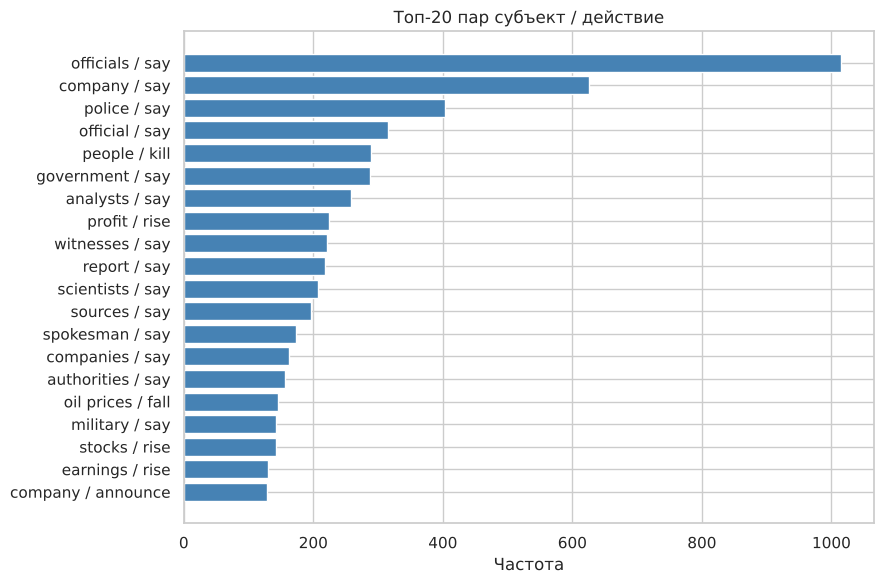

In [30]:
top20 = pairs_df['pair'].value_counts().head(20)

plt.figure(figsize=(9, 6))
plt.barh(top20.index, top20.values, color='steelblue')
plt.gca().invert_yaxis()
plt.title('Топ-20 пар субъект / действие')
plt.xlabel('Частота')
plt.tight_layout()
plt.show()

Пары найдены в 113 092 документах из 120 000 (94%), всего извлечено 265 464 пары, из них 181 968 уникальных. Топ-20 устроен так: 15 пар из 20 это глаголы речи (`officials / say`, `company / say`, `police / say`, `analysts / say`, `company / announce` и другие), и ещё 5 это события: `people / kill`, `profit / rise`, `oil prices / fall`, `stocks / rise`, `earnings / rise`.

По распределению пар по классам видно, что многие из них хорошо указывают на тему. `people / kill` на 99% относится к World, `military / say` на 99%, `police / say` на 88%, `profit / rise`, `stocks / rise` и `oil prices / fall` на 95% к Business, `scientists / say` на 91% к Sci/Tech. Пары с общими субъектами (`company / say`, `companies / say`) делятся поровну между Business и Sci/Tech и почти не встречаются в World и Sports. При этом сама по себе пара с глаголом речи сообщает только об источнике сведений: что именно сказали `officials`, из неё не видно. Так что пары передают, о ком и о чём пишет новость, но не содержание высказывания.

### 5.3 Топ-20 без глаголов речи

Глаголы речи (`say`, `tell`, `add` и подобные) показывают, кто источник сведений, а не что произошло. Убираю их и смотрю на оставшиеся пары.

In [31]:
SPEECH_VERBS = {'say', 'tell', 'add', 'report', 'announce', 'state', 'according', 'claim', 'note'}

event_pairs = pairs_df[~pairs_df['action'].isin(SPEECH_VERBS)]
speech_share = pairs_df['action'].isin(SPEECH_VERBS).mean() * 100
print(f'Доля пар с глаголами речи: {speech_share:.1f}%')

top_pairs(event_pairs)

Доля пар с глаголами речи: 13.4%


category,частота,Business,Sci/Tech,Sports,World
пара,,,,,
people / kill,289,0,0,0,99
profit / rise,224,95,3,0,2
oil prices / fall,145,95,1,0,4
stocks / rise,142,95,1,0,4
earnings / rise,130,94,5,0,1
stocks / fall,128,91,1,0,9
shares / fall,115,90,10,0,1
people / die,108,0,5,1,94
profit / fall,107,97,1,0,2


В общий топ-20 почти не попал класс Sports: в спортивных новостях подлежащие это имена игроков и названия команд, поэтому пары очень разнообразны. Посмотрю на самые частые пары внутри каждого класса и на долю уникальных пар.

In [32]:
per_class = {}
for cat, group in event_pairs.groupby('category'):
    top = group['pair'].value_counts().head(8)
    per_class[cat] = [f'{p} ({n})' for p, n in top.items()]

display(pd.DataFrame(per_class, index=range(1, 9)))

unique_share = event_pairs.groupby('category')['pair'].agg(lambda s: s.nunique() / len(s) * 100)
print('Доля уникальных пар по классам, %:')
print(unique_share.round(1).to_string())

,Business,Sci/Tech,Sports,World
1,profit / rise (213),microsoft / release (66),terms / disclose (24),people / kill (287)
2,oil prices / fall (138),study / find (58),team / have (22),soldiers / kill (104)
3,stocks / rise (135),microsoft / launch (51),team / win (20),people / die (102)
4,earnings / rise (122),microsoft / offer (44),boston red sox / win (19),car bomb / explode (97)
5,stocks / fall (116),scientists / find (42),nl / notable (19),death toll / rise (89)
6,profit / fall (104),study / show (40),goal / give (17),troops / kill (77)
7,shares / fall (103),focus / improve (36),things / go (17),palestinians / kill (65)
8,economy / grow (94),focus / obtain (36),season / end (17),bomb / explode (64)


Доля уникальных пар по классам, %:
category
Business    70.3
Sci/Tech    75.8
Sports      85.0
World       71.0


### 5.4 Тональность глаголов

Оценку тональности беру из словаря VADER (`vader_lexicon`): для каждого глагола-сказуемого смотрю его оценку в словаре, от -4 (сильно негативный) до +4 (сильно позитивный). Для новостей это приближённая проверка: словарь составлен по отзывам и соцсетям и многих новостных глаголов в нём нет, поэтому отдельно считаю долю пар, для которых глагол есть в словаре.

In [33]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)
lexicon = SentimentIntensityAnalyzer().lexicon

pairs_df['score'] = pairs_df['action'].map(lexicon)
scored = pairs_df.dropna(subset=['score'])

tone = pd.DataFrame({
    'пар': pairs_df.groupby('category').size(),
    'глагол в словаре, %': scored.groupby('category').size() / pairs_df.groupby('category').size() * 100,
    'негативных, %': scored[scored['score'] <= -1].groupby('category').size() / scored.groupby('category').size() * 100,
    'позитивных, %': scored[scored['score'] >= 1].groupby('category').size() / scored.groupby('category').size() * 100,
    'с отрицанием, %': pairs_df.groupby('category')['negated'].mean() * 100,
    'в страдательном залоге, %': pairs_df.groupby('category')['passive'].mean() * 100,
}).round(1)
tone

,пар,"глагол в словаре, %","негативных, %","позитивных, %","с отрицанием, %","в страдательном залоге, %"
category,,,,,,
Business,66421,17.0,35.2,39.8,0.7,4.6
Sci/Tech,61592,15.0,31.1,41.1,0.7,6.5
Sports,62757,20.8,34.7,40.1,1.3,6.9
World,74694,23.7,53.8,22.2,1.1,9.0


In [34]:
neg = scored[scored['score'] <= -1]['pair'].value_counts().head(10)
pos = scored[scored['score'] >= 1]['pair'].value_counts().head(10)

pd.DataFrame({
    'негативные пары': [f'{p} ({n})' for p, n in neg.items()],
    'позитивные пары': [f'{p} ({n})' for p, n in pos.items()],
}, index=range(1, 11))

,негативные пары,позитивные пары
1,people / kill (289),oil prices / ease (56)
2,people / die (108),focus / improve (51)
3,soldiers / kill (104),government / agree (35)
4,troops / kill (77),microsoft / expand (30)
5,police / arrest (69),us / agree (27)
6,palestinians / kill (65),economy / expand (27)
7,militants / kill (45),it managers / win (26)
8,car bomb / kill (43),india / agree (25)
9,forces / kill (41),team / win (24)
10,suicide bomber / kill (33),iran / agree (23)


Пары по классам и тональность глаголов показывают следующее.

Содержание. Лучше всего пары отражают суть классов World и Business. В World это насилие и конфликты: `people / kill`, `soldiers / kill`, `people / die`, `car bomb / explode`, `death toll / rise`. В Business это динамика показателей: `profit / rise`, `stocks / fall`, `oil prices / fall`, `economy / grow`. В Sci/Tech пары строятся вокруг компаний и исследований: `microsoft / release`, `microsoft / launch`, `study / find`, `study / show`. Хуже всего пары работают для Sports: доля уникальных пар там 85% против 70-76% в других классах, потому что подлежащие это фамилии игроков и названия команд, и самые частые пары встречаются не больше 24 раз. Пары, которые вошли в верх списка Sports, в основном шаблонные: `terms / disclose` (из фразы `terms were not disclosed` о сделках, 23 из 25 текстов с такой фразой относятся к Sports) и `nl / notable` (из заголовка колонки `NL notables`). Более содержательные пары (`team / win`, `boston red sox / win`) встречаются 19-20 раз.

Искажения. Часть пар в верхе списка создают повторяющиеся шаблонные фразы, а не смысл текстов. Например, пары `focus / improve` и `focus / obtain` в Sci/Tech получаются из одного предложения `This fourth priority's main focus has been improving or obtaining CRM and ERP software`, которое повторяется в 62 документах.

Тональность. По словарю VADER глагол из словаря нашёлся только у 15-24% пар: самые частые глаголы новостей (`say`, `rise`, `fall`, `announce`) в нём не размечены. Среди пар с оценкой в World негативных 54% и позитивных 22%, в остальных классах негативных 31-35% и позитивных около 40%. Самые частые негативные пары это `people / kill`, `people / die`, `soldiers / kill`, `police / arrest`, то есть тональность World связана с насилием и жертвами. В World также больше страдательного залога (9.0% против 4.6% в Business), что соответствует сообщениям о пострадавших. Отрицание встречается в 0.7-1.3% пар и тональность почти не определяет. Словарь при этом иногда ошибается для новостного текста: `oil prices / ease` считается позитивной парой, хотя речь о снижении цены. В Business тональность лучше видна из самой пары: `profit / rise` встречается 224 раза, `profit / fall` 107, `stocks / rise` 142, `stocks / fall` 128, то есть направление изменения заложено в глаголе, а словарь его не видит.

Токсичность. В новостном датасете нет оскорбительной лексики, поэтому токсичность в этих парах проявляется только как тематика насилия (`kill`, `die`, `explode`, `arrest`). Для поиска токсичных высказываний пары субъект / действие не подходят: нужны прилагательные и оценочная лексика.

Итог: пары хорошо отражают тему и участников событий в World и Business, слабо отражают содержание высказываний (из-за глаголов речи) и спортивные новости (из-за имён собственных), а тональность по ним можно оценить лишь частично.

## 6. Разрешение анафоры

Датасет англоязычный, поэтому ищу местоимения третьего лица `he`, `she`, `it`, `they` и их формы в косвенном падеже `him`, `her`, `them`. Русскому `это` соответствует `it`. Притяжательные формы (`his`, `her` в роли определения, `its`, `their`) не заменяю: заменить их на существительное без притяжательной формы нельзя.

У английских существительных нет рода и числа в морфологической разметке, кроме числа (`NNS`, `NNPS` для множественного), поэтому недостающие признаки получаю из других источников:
- число: тег существительного (`NNS`, `NNPS` это множественное число);
- одушевлённость: именованная сущность `PERSON` либо слово, которое в словаре WordNet относится к людям (`player`, `minister`, `spokesman`);
- род: для людей по имени (`gender-guesser`, например `Paolo` мужской, `Kim` женский), по словам вроде `man`, `woman`, `mother`, `wife` и по окончанию `-man` и `-woman`. Если род определить нельзя (например, известна только фамилия), подходит любое местоимение единственного числа;
- коллективные существительные: организации, страны, команды (`ORG`, `GPE`, `NORP` или слово из группы в WordNet) могут быть заменены и на `it`, и на `they`.

Правила алгоритма:
1. Для каждого местоимения собираются кандидаты: существительные и имена собственные, которые стоят раньше местоимения в том же или в двух предыдущих предложениях.
2. Кандидат должен согласовываться с местоимением: `he`, `him` требуют человека мужского рода или неизвестного рода в единственном числе, `she`, `her` женского или неизвестного рода, `it` не человека в единственном числе, `they`, `them` существительного во множественном числе (коллективное существительное допускается, но получает штраф).
3. Кандидат не может быть другим аргументом того же глагола (`John saw him`), подлежащим общего глагола в однородной цепочке (`police arrested X and charged them`) и не может быть предком местоимения в дереве.
4. Из подходящих выбирается кандидат с наименьшей штрафной оценкой. Оценка складывается из синтаксического расстояния (число рёбер дерева зависимостей между кандидатом и местоимением, для кандидата из другого предложения сумма глубин обоих слов в своих деревьях), штрафа 3 за каждое предложение между ними и штрафа 4 за коллективное существительное. Подлежащее получает бонус 3, а подлежащее главного глагола, если местоимение стоит в придаточной части (`X said it will`), ещё дополнительный бонус 4. Если род кандидата известен и совпадает с родом местоимения (`Maria Sharapova` и `she`), бонус 8.
5. Не заменяются безличные `it` (`it is likely that`, `it was confirmed that`, `it is a ...`) и сокращение `it's`.
6. Служебные слова (названия агентств `Reuters`, `AP`, слова в скобках, обозначения времени вроде `year`, `week`) в кандидаты не берутся.

### 6.1 Подготовка

In [35]:
# если библиотек нет: !pip install gender-guesser
import random
import nltk
import gender_guesser.detector as gender_detector
from nltk.corpus import wordnet as wn

nltk.download('wordnet', quiet=True)

nlp_ana = spacy.load('en_core_web_sm')
gender_model = gender_detector.Detector()

PRONOUNS = {'he': 'M', 'him': 'M', 'she': 'F', 'her': 'F', 'it': 'N', 'they': 'P', 'them': 'P'}
MALE_WORDS = {'man', 'men', 'boy', 'boys', 'father', 'husband', 'son', 'brother', 'king', 'gentleman', 'mr', 'prince', 'uncle'}
FEMALE_WORDS = {'woman', 'women', 'girl', 'girls', 'mother', 'wife', 'daughter', 'sister', 'queen', 'lady', 'mrs', 'ms', 'princess', 'aunt'}
AGENCIES = {'Reuters', 'AP', 'AFP', 'Xinhua', 'UPI', 'Bloomberg'}
TIME_NOUNS = {'year', 'day', 'week', 'month', 'time', 'morning', 'night', 'evening', 'afternoon', 'percent', 'quarter', 'half'}
NOT_ANTECEDENT = {'DATE', 'TIME', 'PERCENT', 'MONEY', 'QUANTITY', 'CARDINAL', 'ORDINAL'}
NAMED = {'PERSON', 'ORG', 'GPE', 'NORP', 'LOC', 'FAC', 'PRODUCT', 'EVENT', 'LAW'}
MAX_SENT_BACK = 2

PERSON_SYN = wn.synset('person.n.01')
GROUP_SYN = wn.synset('group.n.01')

### 6.2 Признаки существительных

In [36]:
wn_cache = {}


def wordnet_flags(lemma):
    # (слово обозначает человека, слово обозначает группу)
    if lemma not in wn_cache:
        closure = set()
        for syn in wn.synsets(lemma, 'n')[:2]:
            closure |= set(syn.closure(lambda s: s.hypernyms())) | {syn}
        wn_cache[lemma] = (PERSON_SYN in closure, GROUP_SYN in closure)
    return wn_cache[lemma]


def entity_map(doc):
    mapping = {}
    for ent in doc.ents:
        for t in ent:
            mapping[t.i] = ent
    return mapping


def noun_features(tok, ents):
    ent = ents.get(tok.i)
    label = ent.label_ if ent else ''
    lemma = tok.lemma_.lower()
    is_person, is_group = wordnet_flags(lemma)

    person = label == 'PERSON' or (label == '' and is_person)
    group = label in ('ORG', 'GPE', 'NORP') or (label == '' and is_group)
    plural = tok.tag_ in ('NNS', 'NNPS')

    gender = None
    if person:
        if lemma in MALE_WORDS or lemma.endswith('man'):
            gender = 'M'
        elif lemma in FEMALE_WORDS or lemma.endswith('woman'):
            gender = 'F'
        elif label == 'PERSON' and ent.end - ent.start > 1:
            guess = gender_model.get_gender(ent[0].text)
            gender = {'male': 'M', 'mostly_male': 'M', 'female': 'F', 'mostly_female': 'F'}.get(guess)
    return {'label': label, 'person': person, 'group': group, 'plural': plural, 'gender': gender}


def agreement(pron, feat):
    # 0 не согласуются, 1 согласуются, 2 согласуются как коллективное существительное
    kind = PRONOUNS[pron.text.lower()]
    if feat['label'] in NOT_ANTECEDENT:
        return 0
    if kind in ('M', 'F'):
        return int(feat['person'] and not feat['plural'] and feat['gender'] in (None, kind))
    if kind == 'N':
        return int(not feat['person'] and not feat['plural'])
    if feat['plural']:
        return 1
    return 2 if feat['group'] else 0

### 6.3 Синтаксические функции

In [37]:
def depth(tok):
    d = 0
    while tok.head.i != tok.i:
        tok = tok.head
        d += 1
    return d


def tree_distance(a, b):
    # число рёбер дерева зависимостей между двумя токенами одного предложения
    above_a, t, d = {}, a, 0
    while True:
        above_a[t.i] = d
        if t.head.i == t.i:
            break
        t, d = t.head, d + 1
    t, d = b, 0
    while True:
        if t.i in above_a:
            return above_a[t.i] + d
        if t.head.i == t.i:
            return None
        t, d = t.head, d + 1


def is_impersonal(tok, doc):
    head = tok.head
    if tok.text.lower() != 'it':
        return False
    if tok.dep_ == 'expl' or head.lemma_ in ('seem', 'appear', 'rain', 'snow'):
        return True
    if tok.i + 2 < len(doc) and doc[tok.i + 1].text == "'" and doc[tok.i + 2].text == 's':
        return True
    if head.lemma_ == 'be' and any(c.dep_ in ('attr', 'acomp') for c in head.children):
        return True
    if tok.dep_ == 'nsubjpass' and any(c.dep_ == 'ccomp' for c in head.children):
        return True
    return False


def governing_subject(tok):
    # подлежащее главного глагола, если местоимение стоит в придаточной части
    verb = tok.head
    if tok.dep_ in ('nsubj', 'nsubjpass') and verb.dep_ in ('ccomp', 'xcomp', 'advcl', 'conj') and verb.head.i != verb.i:
        for child in verb.head.children:
            if child.dep_ in ('nsubj', 'nsubjpass'):
                return child
    return None


def noun_phrase(tok, ents):
    ent = ents.get(tok.i)
    if ent and ent.end - 1 == tok.i and ent.label_ in NAMED:
        return ent.text
    parts = [t for t in tok.lefts if t.dep_ == 'compound' and t.text not in AGENCIES and len(t.text) > 1] + [tok]
    text = ' '.join(t.text for t in parts)
    dets = [t for t in tok.lefts if t.dep_ == 'det']
    if dets:
        word = dets[0].text.lower()
        text = ('the ' if word in ('a', 'an', 'the') else dets[0].text + ' ') + text
    return text

### 6.4 Алгоритм разрешения

In [38]:
def resolve_anaphora(doc):
    ents = entity_map(doc)
    sent_id = {}
    for k, sent in enumerate(doc.sents):
        for t in sent:
            sent_id[t.i] = k

    features = {}
    links = []
    for tok in doc:
        if tok.text.lower() not in PRONOUNS or tok.pos_ != 'PRON':
            continue
        if tok.text.lower() == 'her' and tok.tag_ != 'PRP':
            continue
        if is_impersonal(tok, doc):
            continue

        gov_subject = governing_subject(tok)
        best = None
        for cand in doc[:tok.i]:
            if cand.pos_ not in ('NOUN', 'PROPN') or cand.dep_ == 'compound':
                continue
            if cand.text in AGENCIES or len(cand.text) < 2 or not any(ch.isalpha() for ch in cand.text):
                continue
            if cand.lemma_.lower() in TIME_NOUNS or (cand.i > 0 and doc[cand.i - 1].text == '('):
                continue
            gap = sent_id[tok.i] - sent_id[cand.i]
            if gap > MAX_SENT_BACK:
                continue

            if cand.i not in features:
                features[cand.i] = noun_features(cand, ents)
            match = agreement(tok, features[cand.i])
            if not match:
                continue

            if gap == 0:
                if cand.head.i == tok.head.i or tok in cand.subtree:
                    continue
                if cand.dep_ in ('nsubj', 'nsubjpass') and tok.head.dep_ == 'conj' and cand.head.i == tok.head.head.i                         and not any(c.dep_ in ('nsubj', 'nsubjpass') for c in tok.head.children):
                    continue
                dist = tree_distance(cand, tok)
                if dist is None:
                    continue
            else:
                dist = depth(cand) + depth(tok) + 2

            score = dist + 3 * gap + (match - 1) * 4
            if cand.dep_ in ('nsubj', 'nsubjpass'):
                score -= 3
            if gov_subject is not None and cand.i == gov_subject.i:
                score -= 4
            if features[cand.i]['gender'] == PRONOUNS[tok.text.lower()]:
                score -= 8

            if best is None or score < best[0] or (score == best[0] and cand.i > best[1].i):
                best = (score, cand)

        if best:
            links.append({'pron': tok, 'noun': best[1], 'text': noun_phrase(best[1], ents)})
    return links


def replace_pronouns(sent, links):
    new = {l['pron'].i: l['text'] for l in links}
    words = []
    for t in sent:
        if t.i in new:
            w = new[t.i]
            if t.i == sent.start:
                w = w[0].upper() + w[1:]
            words.append(w)
        else:
            words.append(t.text)
    return ' '.join(words)

### 6.5 Проверка на небольших примерах

In [39]:
checks = [
    'Microsoft said on Monday that it will release the update next week .',
    'The coach praised Maria Sharapova after she won the final .',
    'Police arrested two men on Friday and charged them with fraud .',
    'The players said they were tired , but the coach told them to continue .',
    'Prime Minister Tony Blair met President Bush , and he said it was a good meeting .',
]

for text in checks:
    doc = nlp_ana(Doc(nlp_ana.vocab, words=text.split()))
    links = resolve_anaphora(doc)
    print(text)
    print(replace_pronouns(doc[:], links))
    print()

Microsoft said on Monday that it will release the update next week .
Microsoft said on Monday that Microsoft will release the update next week .

The coach praised Maria Sharapova after she won the final .
The coach praised Maria Sharapova after Maria Sharapova won the final .

Police arrested two men on Friday and charged them with fraud .
Police arrested two men on Friday and charged men with fraud .

The players said they were tired , but the coach told them to continue .
The players said the players were tired , but the coach told the players to continue .

Prime Minister Tony Blair met President Bush , and he said it was a good meeting .
Prime Minister Tony Blair met President Bush , and Tony Blair said it was a good meeting .



### 6.6 Применение к текстам датасета

Разбираю случайную выборку из 3000 документов Train.

In [40]:
ana_sample = train_df.sample(3000, random_state=RANDOM_STATE)
ana_docs = list(nlp_ana.pipe((Doc(nlp_ana.vocab, words=t) for t in ana_sample['tokens']), batch_size=256))

found, replaced = Counter(), Counter()
examples = []
for doc in ana_docs:
    for tok in doc:
        if tok.text.lower() in PRONOUNS and tok.pos_ == 'PRON' and not (tok.text.lower() == 'her' and tok.tag_ != 'PRP'):
            found[tok.text.lower()] += 1
    links = resolve_anaphora(doc)
    for l in links:
        replaced[l['pron'].text.lower()] += 1
    for sent in doc.sents:
        sent_links = [l for l in links if sent.start <= l['pron'].i < sent.end]
        if sent_links:
            examples.append({
                'замены': '; '.join(f"{l['pron'].text} = {l['text']}" for l in sent_links),
                'исходное': sent.text,
                'изменённое': replace_pronouns(sent, sent_links),
            })

stats = pd.DataFrame({'найдено': found, 'заменено': replaced}).fillna(0).astype(int)
stats.loc['всего'] = stats.sum()
stats['заменено, %'] = (stats['заменено'] / stats['найдено'] * 100).round(1)
stats

,найдено,заменено,"заменено, %"
it,458,357,77.9
they,155,151,97.4
he,211,186,88.2
him,50,46,92.0
them,59,58,98.3
she,31,26,83.9
her,12,11,91.7
всего,976,835,85.6


### 6.7 Сравнение исходных и изменённых предложений

In [41]:
random.seed(RANDOM_STATE)
pd.set_option('display.max_colwidth', None)
pd.DataFrame(random.sample(examples, 15), index=range(1, 16))

,замены,исходное,изменённое
1,he = Greg Rusedski,Rusedski convinced captain Jeremy Bates he deserved the chance to play Austria ' s,Rusedski convinced captain Jeremy Bates Greg Rusedski deserved the chance to play Austria ' s
2,they = Alitalia unions,"Alitalia unions get pay warning The Italian government warns the unions at airline Alitalia that if they do not agree to pay cuts , the carrier could go bankrupt within a month .","Alitalia unions get pay warning The Italian government warns the unions at airline Alitalia that if Alitalia unions do not agree to pay cuts , the carrier could go bankrupt within a month ."
3,he = Wayne Rooney,"Rooney counting down to Old Trafford debut Wayne Rooney will begin his Manchester United career , ahead of schedule , on Wednesday when he is named among the substitutes for the Champions League match against Fenerbahce","Rooney counting down to Old Trafford debut Wayne Rooney will begin his Manchester United career , ahead of schedule , on Wednesday when Wayne Rooney is named among the substitutes for the Champions League match against Fenerbahce"
4,it = Hurricane Jeanne,"- Hurricane Jeanne got stronger , bigger and faster as it battered the Bahamas and bore down on Florida Saturday , sending huge waves crashing onto beaches and forcing thousands into shelters just weeks after Frances ravaged this area .","- Hurricane Jeanne got stronger , bigger and faster as Hurricane Jeanne battered the Bahamas and bore down on Florida Saturday , sending huge waves crashing onto beaches and forcing thousands into shelters just weeks after Frances ravaged this area ."
5,she = the guest,"When a guest at a plush dinner in Geneva asked where Kinshasa was , she set off a chain of events that led to one of the world ' s great sporting showdowns .","When a guest at a plush dinner in Geneva asked where Kinshasa was , the guest set off a chain of events that led to one of the world ' s great sporting showdowns ."
6,it = family,"Bennett ' s family vows to fight against jail sentence The family of Roy Bennett , the Zimbabwean opposition member of parliament who was jailed yesterday on charges of parliamentary misconduct , says it will appeal against the decision .","Bennett ' s family vows to fight against jail sentence The family of Roy Bennett , the Zimbabwean opposition member of parliament who was jailed yesterday on charges of parliamentary misconduct , says family will appeal against the decision ."
7,he = Matthew Emmons,The American sharpshooter was just one shot away from a second Olympic gold medal when he fired at the wrong target in the final round .,The American sharpshooter was just one shot away from a second Olympic gold medal when Matthew Emmons fired at the wrong target in the final round .
8,He = Michael Eisner; he = Michael Eisner; him = Michael Eisner,"He ' d just survived emergency bypass surgery , and he was worried : if something happened to him , who could possibly run Disney ?","Michael Eisner ' d just survived emergency bypass surgery , and Michael Eisner was worried : if something happened to Michael Eisner , who could possibly run Disney ?"
9,it = rookie season,AFC : Winslow leads Browns ' injury woes Kellen Winslow ' s hyped rookie season might be over after it barely began - much like a promising season for the Cleveland Browns .,AFC : Winslow leads Browns ' injury woes Kellen Winslow ' s hyped rookie season might be over after rookie season barely began - much like a promising season for the Cleveland Browns .
10,they = scientists,"Cassini spacecraft images of Saturn ' s moon befuddling After staying up much of the night analyzing the first close-up images of Titan ' s smog-shrouded surface , groggy scientists acknowledged yesterday that they were befuddled","Cassini spacecraft images of Saturn ' s moon befuddling After staying up much of the night analyzing the first close-up images of Titan ' s smog-shrouded surface , groggy scientists acknowledged yesterday that scientists were befudd

### 6.8 Выборка для ручной проверки

Для оценки точности просматриваю вручную 50 случайных предложений с заменами: смотрю, правильно ли выбрано существительное, на которое указывает местоимение.

In [42]:
random.seed(123)
check = random.sample(examples, 50)
pd.DataFrame(check, index=range(1, 51))[['замены', 'изменённое']]

,замены,изменённое
1,it = Russia Must Save Energy Windfall WASHINGTON - - The International Monetary Fund,IMF Says Russia Must Save Energy Windfall WASHINGTON - - The International Monetary Fund on Wednesday raised its outlook for Russia ' s economy but warned Moscow to resist spending the extra oil revenues Russia Must Save Energy Windfall WASHINGTON - - The International Monetary Fund has received as a result of record energy prices .
2,they = Reuters - Serbs,Reuters - Serbs went to the polls in local elections on Sunday in the first test of voter opinion since Reuters - Serbs chose pro-Western President Boris Tadic in June .
3,he = Jonah Lomu,"Lomu Says Kidney Transplant Working , Targets Rugby World Cup Jonah Lomu , the leading try scorer in rugby World Cups , said Jonah Lomu ' s returning to full health after a kidney transplant six weeks ago ."
4,he = Steve Ballmer,"Ballmer : Windows Safer than Linux Microsoft CEO Steve Ballmer on Wednesday plunged headfirst into the controversial waters of comparing the benefits and advantages of the Windows platform with Unix and Linux in an executive e-mail Steve Ballmer sent to customers , partners and subscribers ."
5,they = lights; they = lights,Aggies dim lights on Iowa State ' s party There was irritation among some Texas A & M players this week when lights learned lights were the opponent for the Iowa State homecoming game .
6,they = computers,"is recalling about [NUM] million AC adapters nationwide_ [NUM] million worldwide_ used with notebook personal computers because computers can overheat and cause a fire and electrical shock hazard , the company and the Consumer Product Safety Commission said Friday ."
7,it = BBVA,BBVA announced Tuesday BBVA plans to buy Laredo National Bancshares for $ [NUM] million .
8,they = the eyes,"It is time for redemption in the eyes of heavyweights Wladimir Klitschko and DaVarryl Williamson when the eyes collide this Saturday October 2nd in the new outdoor Amphitheatre at Caesars Palace in Las Vegas , Nevada ."
9,he = Anthony Williams,Washington Mayor Says Council Puts Baseball in Capital at Risk A grim Mayor Anthony Williams said today that Anthony Williams was deeply pessimistic that Washington would be able to salvage its deal with Major League Baseball to bring the Montreal
10,it = the UK products company,"4bn deal Kidde , the UK fire and safety products company , said yesterday the UK products company had accepted a cash offer from United Technology Corporation that values the group at [NUM] . 442bn ."


В выборке из 3000 документов найдено 976 местоимений третьего лица, алгоритм заменил 835 из них (86%). Чаще всего заменялись `they` и `them` (97-98%), `he` и `him` (88-92%). Реже всего `it` (78%): неличное `it` в конструкциях вроде `it is likely that`, `it was confirmed that`, `it's` я не заменяю, потому что оно не указывает на существительное.

Результат замены хорошо видно на сравнении предложений. Например, `Microsoft said on Monday that it will release the update` превращается в `Microsoft said on Monday that Microsoft will release the update`, а `Gerrard ... but is hopeful he will be ready` в `... is hopeful Steven Gerrard will be ready`. После замены ссылка на объект становится явной, и предложение можно понять без соседних, но текст получается повторяющимся и менее естественным, чем с местоимениями.

Точность проверена вручную на 50 случайных предложениях с заменами (56 замен). Верный объект выбран в 36 случаях, около 64%, но качество сильно зависит от местоимения:
- `he`, `him`, `she`, `her`: верно 18 из 19 (около 95%). Здесь работает согласование: нужен одушевлённый кандидат в единственном числе, а род (по имени и по словам вроде `wife`) отсекает неподходящих. В новостях такие местоимения обычно относятся к ближайшему человеку и подлежащему, поэтому правила работают хорошо;
- `it`: верно 12 из 21 (около 57%). Ошибки возникают, когда `it` относится к организации, которая не является подлежащим (`Iran banned National Geographic until it corrects an atlas`, где `it` это `National Geographic`), к ситуации или к целому утверждению (`if you can call it that`), и в предложениях с оборванным началом;
- `they`, `them`: верно 6 из 16 (около 38%). Самая частая ошибка: `they` относится к двум людям или к группе, названной через несколько слов (`Hewitt and Henman ... they`, `Aggies ... players ... they`), а алгоритм выбирает ближайшее существительное во множественном числе (`men`, `lights`, `eyes`).

Другие источники ошибок связаны с нашим текстом. Заголовки в начале документов, набранные с заглавных букв, дают неверные именованные сущности, и в результате вместо имени подставляется кусок заголовка (`Russia Must Save Energy Windfall WASHINGTON - - The International Monetary Fund`). Усечённые предложения без подлежащего тоже ведут к неверному выбору. Принципиальное ограничение метода: алгоритм подставляет только существительные и не работает, когда местоимение относится к целой ситуации или предложению, а окно поиска ограничено тремя предложениями.

Вывод: правила на основе согласования по роду и числу и синтаксического расстояния достаточно надёжно разрешают `he` и `she`, неплохо справляются с `it` для подлежащего-организации и слабо работают для `they`. Для улучшения нужны данные о кореферентности (слова-антецеденты из конъюнкций, группы) или обученная модель, которой правила не хватает.